# RAG en 45 minutes : de vos documents à des réponses sourcées

**RodiumAi Bootcamp · Module RAG « Connecter documents et IA »**

Ce notebook accompagne la présentation. Il construit, pas à pas, un petit système RAG qui répond
à des questions sur un document, **cite ses sources** et sait dire **« je ne sais pas »**.

| Étape | Ce que vous faites | Diapositive associée |
| --- | --- | --- |
| 1 | Lire le document | Le pipeline |
| 2 | Le découper en chunks | Chunking |
| 3 | Transformer les chunks en vecteurs | Embeddings |
| 4 | Chercher : mots-clés, vecteurs, hybride | Base vectorielle · Pour aller plus loin |
| 5 | Générer la réponse avec un prompt strict | Le prompt d'augmentation |
| 6 | Contrôler les citations et évaluer | Évaluation |
| 7 | **À vous** : le même système sur votre document | Exercice |

**Choix pédagogique :** aucun framework. Chaque brique tient en quelques lignes que vous pouvez lire,
modifier et expliquer. Une fois le principe compris, passer à LangChain ou LlamaIndex devient facile.

### Avant de commencer

- Exécutez les cellules **dans l'ordre** (`Maj + Entrée`).
- La **recherche tourne en local**, sans clé API et sans frais.
- Seule l'**étape 5** (rédaction de la réponse) a besoin d'un modèle de langage. **Sans clé API, le notebook
  affiche le prompt** : vous pouvez le coller dans n'importe quel assistant et voir la même chose.
- Le document d'exemple est **fictif** : il a été écrit pour cette formation.

In [ ]:
%pip install -q sentence-transformers rank_bm25 openai pypdf

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 402.7/402.7 kB 7.8 MB/s eta 0:00:00


### Les schémas

Chaque étape est accompagnée d'un **schéma**. Une cellule technique les dessine : exécutez-la une fois,
inutile de lire son code (Colab l'a masqué ; cliquez sur « Afficher le code » si vous êtes curieux).

In [ ]:
#@title 🎨 Schémas illustratifs (cellule technique, inutile de la lire) { display-mode: "form" }
import math
from IPython.display import SVG, display

ORANGE, SOMBRE, GRIS, VERT, ROSE, ROUGE = "#FF5F00", "#0E0F12", "#6B7078", "#1B9C85", "#D1578F", "#D63A3A"
POLICE = "Arial, Helvetica, sans-serif"

def _txt(x, y, contenu, taille=15, gras=False, couleur=SOMBRE, ancre="middle"):
    poids = 700 if gras else 400
    return (f'<text x="{x}" y="{y}" font-family="{POLICE}" font-size="{taille}" '
            f'font-weight="{poids}" fill="{couleur}" text-anchor="{ancre}">{contenu}</text>')

def _boite(x, y, l, h, lignes, fond="#FFFFFF", bord=SOMBRE, couleur=SOMBRE, couleur2=GRIS,
           taille=15, rayon=10, epaisseur=1.5):
    """Rectangle arrondi avec texte centré : 1re ligne en gras, les suivantes en plus petit."""
    lignes = [lignes] if isinstance(lignes, str) else lignes
    pas = taille + 5
    y0 = y + h / 2 - (len(lignes) - 1) * pas / 2 + taille * 0.35
    out = (f'<rect x="{x}" y="{y}" width="{l}" height="{h}" rx="{rayon}" fill="{fond}" '
           f'stroke="{bord}" stroke-width="{epaisseur}"/>')
    for i, ligne in enumerate(lignes):
        out += _txt(x + l / 2, y0 + i * pas, ligne, taille if i == 0 else taille - 2,
                    i == 0, couleur if i == 0 else couleur2)
    return out

def _fleche(x1, y1, x2, y2, gris=False):
    marque = "pointeg" if gris else "pointe"
    couleur = GRIS if gris else ORANGE
    return (f'<line x1="{x1}" y1="{y1}" x2="{x2}" y2="{y2}" stroke="{couleur}" '
            f'stroke-width="2.5" marker-end="url(#{marque})"/>')

def _svg(largeur, hauteur, corps):
    defs = "<defs>" + "".join(
        f'<marker id="{nom}" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="6" markerHeight="6" '
        f'orient="auto"><path d="M0,0 L10,5 L0,10 z" fill="{couleur}"/></marker>'
        for nom, couleur in (("pointe", ORANGE), ("pointeg", GRIS))) + "</defs>"
    return (f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {largeur} {hauteur}" '
            f'width="{largeur}" height="{hauteur}" style="max-width:100%;height:auto">{defs}'
            f'<rect x="0.5" y="0.5" width="{largeur - 1}" height="{hauteur - 1}" rx="16" '
            f'fill="#FFFFFF" stroke="#D9D5CA"/>{corps}</svg>')

# ───────── 1. Vue d'ensemble du pipeline ─────────
def schema_pipeline():
    c = _txt(30, 34, "INGESTION · une seule fois par document", 14, True, GRIS, "start")
    etapes = [("Document", "PDF, texte"), ("Découpage", "chunks + en-tête"),
              ("Embeddings", "un vecteur par chunk"), ("Base vectorielle", "stocke les vecteurs")]
    for i, (nom, detail) in enumerate(etapes):
        x = 30 + i * 230
        c += _boite(x, 50, 170, 70, [nom, detail], fond="#FFF1E8", bord=ORANGE)
        if i < 3:
            c += _fleche(x + 172, 85, x + 228, 85)
    c += _txt(30, 188, "QUESTION-RÉPONSE · à chaque question", 14, True, GRIS, "start")
    etapes = [("Question", "de l'utilisateur"), ("Embedding", "même modèle"), ("Recherche", "les k meilleurs"),
              ("Prompt", "règles + passages"), ("LLM", "rédige la réponse"), ("Réponse", "avec sources")]
    for i, (nom, detail) in enumerate(etapes):
        x = 30 + i * 150
        dernier = i >= 4
        c += _boite(x, 205, 118, 70, [nom, detail], taille=14,
                    fond=ORANGE if dernier else "#EEEDE8", bord=ORANGE if dernier else GRIS,
                    couleur="#FFFFFF" if dernier else SOMBRE, couleur2="#FFFFFF" if dernier else GRIS)
        if i < 5:
            c += _fleche(x + 120, 240, x + 148, 240)
    c += (f'<path d="M805,122 V160 H389 V203" fill="none" stroke="{GRIS}" stroke-width="2.5" '
          f'stroke-dasharray="7 6" marker-end="url(#pointeg)"/>')
    c += _txt(600, 152, "la recherche lit la base vectorielle", 12, False, GRIS)
    return _svg(920, 305, c)

# ───────── 2. Découpage ─────────
def schema_chunking():
    c = _txt(30, 32, "TAILLE FIXE : on coupe tous les N caractères, sans comprendre le texte", 14, True, GRIS, "start")
    morceaux = [["Article 3 · Plafonds", "Un compte standard permet", "d'envoyer au maxi"],
                ["mum 200 000 FCFA par jour.", "Un compte vérifié, dont", "l'ident"],
                ["ité a été contrôlée en", "agence, permet d'envoyer", "jusqu'à 1 500 000 FCFA"],
                ["par jour.", "Article 4 · Frais", "Les envois entre comptes"]]
    for i, lignes in enumerate(morceaux):
        x = 30 + i * 215
        c += f'<rect x="{x}" y="46" width="215" height="84" fill="{"#FFF1E8" if i % 2 == 0 else "#FFE3D1"}"/>'
        for j, ligne in enumerate(lignes):
            c += _txt(x + 107, 70 + j * 19, ligne, 12)
    c += f'<rect x="30" y="46" width="860" height="84" fill="none" stroke="{ORANGE}" stroke-width="1.5"/>'
    for x in (245, 460, 675):
        c += f'<line x1="{x}" y1="40" x2="{x}" y2="136" stroke="{ROUGE}" stroke-width="3" stroke-dasharray="6 4"/>'
    c += _txt(30, 160, "Le montant « 200 000 FCFA » est séparé de « compte standard » : le contexte est perdu.",
              14, True, ROUGE, "start")

    c += _txt(30, 205, "PAR ARTICLE : un chunk = un article, avec un en-tête et un identifiant", 14, True, GRIS, "start")
    blocs = [("A2", "Ouverture d'un compte", ["Pièce d'identité valide,", "téléphone actif, code PIN", "à quatre chiffres."]),
             ("A3", "Plafonds", ["Un compte standard permet", "200 000 FCFA par jour.", "Un compte vérifié :", "1 500 000 FCFA par jour."]),
             ("A4", "Frais", ["Envois gratuits jusqu'à", "5 000 FCFA. Au-delà,", "des frais de 1 %", "s'appliquent."]),
             ("A5", "Retrait d'espèces", ["Code de retrait à six", "chiffres, valable", "30 minutes."])]
    for i, (ident, titre, lignes) in enumerate(blocs):
        x = 30 + i * 218.3
        c += f'<rect x="{x:.1f}" y="222" width="205" height="136" rx="10" fill="#FFFFFF" stroke="{ORANGE}" stroke-width="1.5"/>'
        c += f'<path d="M{x:.1f},258 V232 a10,10 0 0 1 10,-10 H{x + 195:.1f} a10,10 0 0 1 10,10 V258 Z" fill="{ORANGE}"/>'
        c += _txt(x + 102.5, 239, "Guide AfriPay", 11, False, "#FFFFFF")
        c += _txt(x + 102.5, 253, f"Article {ident[1:]} · {titre}", 11, True, "#FFFFFF")
        for j, ligne in enumerate(lignes):
            c += _txt(x + 14, 282 + j * 17, ligne, 12, False, SOMBRE, "start")
        c += _txt(x + 192, 348, f"[{ident}]", 13, True, ORANGE, "end")
    c += _txt(30, 388, "Chaque chunk se comprend seul, garde son sujet dans l'en-tête et porte un id pour être cité.",
              14, True, VERT, "start")
    return _svg(920, 405, c)

# ───────── 3. Embeddings ─────────
def schema_embeddings():
    c = ""
    phrases = ["J'ai promené mon <tspan font-weight=\"700\">chien</tspan>",
               "Il va pleuvoir <tspan font-weight=\"700\">aujourd'hui</tspan>",
               "J'ai promené mon <tspan font-weight=\"700\">chat</tspan>"]
    styles = [("#FFE3D1", ORANGE), ("#D5F0EA", VERT), ("#EEEDE8", GRIS)]
    valeurs = [[0.2, 0.6, 1.7, 2.4, 0.5, 6.1], [0.9, 2.4, 7.2, 1.7, 0.8, 0.1], [0.2, 0.5, 1.5, 2.3, 0.6, 5.8]]
    centres = [76, 191, 306]
    for i in range(3):
        fond, bord = styles[i]
        cy = centres[i]
        c += f'<rect x="25" y="{cy - 31}" width="300" height="62" rx="10" fill="{fond}" stroke="{bord}" stroke-width="1.8"/>'
        c += _txt(42, cy + 6, phrases[i], 18, ancre="start")
        c += _fleche(328, cy, 386, 170 + i * 35)
        c += _fleche(594, 170 + i * 35, 636, cy)
        for j, v in enumerate(valeurs[i]):
            x = 640 + j * 50
            c += f'<rect x="{x}" y="{cy - 20}" width="48" height="40" fill="{fond}" stroke="{bord}" stroke-width="1.5"/>'
            c += _txt(x + 24, cy + 6, f"{v}", 15, True)
    c += _boite(390, 118, 200, 174, ["Encodeur", "(modèle d'embeddings)", "multilingual-e5"],
                fond=ROSE, bord=ROSE, couleur="#FFFFFF", couleur2="#FFFFFF", taille=18, rayon=14)
    c += _txt(480, 366, "Sens proche → vecteurs proches. Sens éloigné → vecteur éloigné.", 16, True, SOMBRE)
    c += _txt(480, 394, "Valeurs illustratives : un vrai vecteur de multilingual-e5-small compte 384 nombres.", 13, False, GRIS)
    return _svg(960, 415, c)

# ───────── 4. Recherche dans l'espace des vecteurs ─────────
def _etoile(cx, cy, r):
    points = []
    for k in range(10):
        rayon = r if k % 2 == 0 else r * 0.45
        angle = -math.pi / 2 + k * math.pi / 5
        points.append(f"{cx + rayon * math.cos(angle):.1f},{cy + rayon * math.sin(angle):.1f}")
    return f'<polygon points="{" ".join(points)}" fill="{ROSE}" stroke="#FFFFFF" stroke-width="1.5"/>'

def schema_recherche():
    c = f'<rect x="30" y="30" width="640" height="340" rx="12" fill="#FBFAF6" stroke="#D9D5CA"/>'
    c += f'<circle cx="270" cy="200" r="88" fill="#E6F5F1" stroke="{VERT}" stroke-width="2" stroke-dasharray="7 5"/>'
    proches = {"A3": (250, 160), "A4": (322, 214), "A8": (205, 236)}
    autres = {"A5": (110, 110), "A12": (400, 100), "A1": (520, 80), "A10": (610, 130), "A2": (590, 215),
              "A11": (505, 195), "A6": (470, 305), "A7": (370, 325), "A9": (595, 305)}
    for ident, (x, y) in autres.items():
        c += f'<circle cx="{x}" cy="{y}" r="8" fill="#C9C6BE"/>' + _txt(x, y - 14, ident, 12, False, GRIS)
    for ident, (x, y) in proches.items():
        c += f'<circle cx="{x}" cy="{y}" r="10" fill="{ORANGE}"/>' + _txt(x, y - 16, ident, 14, True, ORANGE)
    c += _etoile(270, 200, 16) + _txt(270, 232, "question", 13, True, ROSE)
    c += _txt(350, 395, "Chaque point est un chunk. Plus deux points sont proches, plus leur sens est proche.", 13, False, GRIS)
    c += _txt(350, 413, "(Représentation en 2D d'un espace à 384 dimensions.)", 13, False, GRIS)
    for i, (titre, detail) in enumerate([("1 · La question", "devient un point"),
                                          ("2 · On mesure", "la distance aux chunks"),
                                          ("3 · On garde les k", "plus proches : le top-k")]):
        c += _boite(700, 50 + i * 100, 190, 76, [titre, detail], fond="#FFFFFF", bord=VERT if i == 2 else GRIS)
    return _svg(920, 430, c)

# ───────── 5. Recherche hybride et fusion RRF ─────────
def schema_hybride():
    c = f'<rect x="20" y="22" width="450" height="312" rx="14" fill="#FBFAF6" stroke="#D9D5CA"/>'
    colonnes = [(40, "BM25", "mots identiques", ["A8", "A3", "A5"]),
                (255, "Dense", "sens (embeddings)", ["A3", "A4", "A8"])]
    for x, titre, detail, ids in colonnes:
        c += _txt(x + 100, 52, titre, 18, True) + _txt(x + 100, 72, detail, 13, False, GRIS)
        for i, ident in enumerate(ids):
            c += _boite(x, 90 + i * 70, 200, 56, f"{i + 1} · {ident}", fond="#FFFFFF", bord=GRIS, taille=17)
    c += _fleche(472, 180, 520, 180)
    c += _txt(705, 52, "Fusion RRF", 18, True, ORANGE) + _txt(705, 72, "somme de 1 / (60 + rang)", 13, False, GRIS)
    lignes = [("A3", "1/61 + 1/62 = 0,0325", True), ("A8", "1/61 + 1/63 = 0,0323", True),
              ("A4", "1/62 = 0,0161", True), ("A5", "1/63 = 0,0159", False)]
    for i, (ident, calcul, retenu) in enumerate(lignes):
        c += _boite(525, 90 + i * 60, 360, 50, f"{ident} : {calcul}" + ("" if retenu else "  (hors top 3)"),
                    fond="#FFE3D1" if retenu else "#EEEDE8", bord=ORANGE if retenu else GRIS, taille=16)
    c += _txt(30, 366, "Un chunk bien classé par les deux méthodes (A3, A8) passe devant ceux que l'une seule a bien classés (A4, A5).",
              14, True, SOMBRE, "start")
    c += _txt(30, 390, "Exemple illustratif. Les rangs sont ceux de la colonne : 1er = 1/61, 2e = 1/62, 3e = 1/63.", 13, False, GRIS, "start")
    return _svg(920, 408, c)

# ───────── 6. Construction du prompt ─────────
def schema_prompt():
    c = ""
    blocs = [(40, 104, "#FFF1E8", ORANGE, ["1 · Règles", "Réponds uniquement avec les passages.", "Sinon écris INFORMATION ABSENTE.", "Cite l'id [A3] après chaque affirmation."]),
             (162, 104, "#E6F5F1", VERT, ["2 · Passages retrouvés", "[A4] Les envois entre comptes AfriPay", "sont gratuits jusqu'à 5 000 FCFA…", "[A3] Un compte standard permet…"]),
             (284, 76, "#EEEDE8", GRIS, ["3 · Question", "Combien coûte l'envoi de 20 000 FCFA ?"])]
    for y, h, fond, bord, lignes in blocs:
        c += f'<rect x="30" y="{y}" width="310" height="{h}" rx="10" fill="{fond}" stroke="{bord}" stroke-width="1.5"/>'
        c += _txt(46, y + 26, lignes[0], 15, True, SOMBRE, "start")
        for j, ligne in enumerate(lignes[1:]):
            c += _txt(46, y + 50 + j * 20, ligne, 13, False, SOMBRE, "start")
    for y_depart, y_arrivee in ((92, 190), (214, 215), (322, 245)):
        c += _fleche(342, y_depart, 382, y_arrivee)
    c += _boite(386, 150, 140, 130, ["Prompt", "enrichi"], fond=SOMBRE, bord=SOMBRE, couleur="#FFFFFF",
                couleur2="#FFFFFF", taille=18, rayon=14)
    c += _fleche(528, 215, 566, 215)
    c += _boite(570, 175, 96, 80, "LLM", fond=ORANGE, bord=ORANGE, couleur="#FFFFFF", taille=20, rayon=14)
    c += _fleche(668, 205, 706, 140) + _fleche(668, 225, 706, 290)
    c += _boite(710, 92, 180, 96, ["Réponse sourcée", "« … des frais de 1 % [A4] »"],
                fond="#E6F5F1", bord=VERT, taille=15, couleur2=SOMBRE)
    c += _boite(710, 242, 180, 96, ["INFORMATION ABSENTE", "si les passages", "ne suffisent pas"],
                fond="#EEEDE8", bord=GRIS, taille=13)
    c += _txt(30, 392, "Les règles rendent la réponse vérifiable : ancrée dans les passages, citée, ou un refus honnête.",
              14, True, SOMBRE, "start")
    return _svg(920, 412, c)

# ───────── 7. Évaluation ─────────
def schema_evaluation():
    c = _txt(30, 36, "1 · hit@k : le bon passage est-il dans le top-k ?", 16, True, SOMBRE, "start")
    c += _txt(30, 62, "Question : « Que signifie l'erreur E-204 ? »", 14, False, SOMBRE, "start")
    c += _txt(30, 84, "Article attendu : A8", 14, True, ORANGE, "start")
    for i, (ident, juste) in enumerate([("A3", False), ("A8", True), ("A4", False)]):
        y = 104 + i * 62
        c += _boite(30, y, 250, 50, f"rang {i + 1} · {ident}", fond="#E6F5F1" if juste else "#FFFFFF",
                    bord=VERT if juste else GRIS, taille=16)
        c += _boite(292, y + 7, 112, 36, "trouvé" if juste else "pas lui", fond=VERT if juste else "#EEEDE8",
                    bord=VERT if juste else GRIS, couleur="#FFFFFF" if juste else GRIS, taille=14, rayon=18)
    c += _txt(30, 316, "hit@1 = 0  ·  hit@3 = 1", 17, True, SOMBRE, "start")
    c += f'<line x1="450" y1="30" x2="450" y2="330" stroke="#D9D5CA" stroke-width="1.5"/>'
    c += _txt(480, 36, "2 · Les citations sont-elles réelles ?", 16, True, SOMBRE, "start")
    c += _txt(480, 62, "Passages fournis au modèle :", 14, False, SOMBRE, "start")
    c += _boite(480, 72, 70, 34, "A8", fond="#EEEDE8", bord=GRIS, taille=15) + _boite(560, 72, 70, 34, "A3", fond="#EEEDE8", bord=GRIS, taille=15)
    for i, (texte, ok) in enumerate([("« …solde insuffisant [A8] »", True), ("« …voir l'article [A9] »", False)]):
        y = 134 + i * 86
        c += _boite(480, y, 290, 56, texte, fond="#FFFFFF", bord=VERT if ok else ROUGE, taille=15)
        c += _boite(782, y + 10, 108, 36, "valide" if ok else "inventée", fond=VERT if ok else ROUGE,
                    bord=VERT if ok else ROUGE, couleur="#FFFFFF", taille=14, rayon=18)
    c += _txt(480, 316, "[A9] ne fait pas partie des passages fournis.", 13, False, GRIS, "start")
    c += _txt(460, 366, "Si le bon passage n'est pas dans le top-k, aucun prompt ne sauvera la réponse.", 15, True, ORANGE)
    return _svg(920, 392, c)

SCHEMAS = {"pipeline": schema_pipeline, "chunking": schema_chunking, "embeddings": schema_embeddings,
           "recherche": schema_recherche, "hybride": schema_hybride, "prompt": schema_prompt,
           "evaluation": schema_evaluation}

def schema(nom):
    """Affiche le schéma `nom` : pipeline, chunking, embeddings, recherche, hybride, prompt, evaluation."""
    display(SVG(data=SCHEMAS[nom]()))

## Vue d'ensemble : le pipeline

Un RAG se compose de **deux flux**. L'**ingestion** prépare la base une seule fois ; la **question-réponse**
s'exécute à chaque question. Nous allons construire chaque brique, dans l'ordre du schéma.

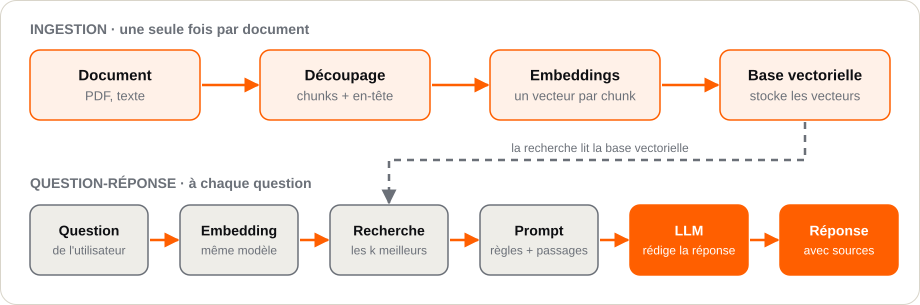

In [ ]:
schema("pipeline")

## Configuration

Deux modèles interviennent dans un RAG, et ils n'ont pas le même rôle :

| Modèle | Rôle | Où il tourne |
| --- | --- | --- |
| **Embeddings** | transformer du texte en vecteurs pour *retrouver* les bons passages | ici, en local |
| **LLM** | *rédiger* la réponse à partir des passages | via une API (optionnel ici) |

Pour le LLM, renseignez la clé dans les **secrets Colab** (icône 🔑 à gauche) sous le nom `LLM_API_KEY`,
puis complétez `MODELE_LLM` (et `BASE_URL` si votre fournisseur utilise une adresse particulière, par exemple
l'API fournie pour le bootcamp). Tant que ces valeurs restent vides, le notebook fonctionne en **mode sans API**.

In [ ]:
import os
import re
import numpy as np

# ── Le modèle qui RÉDIGE la réponse (API compatible OpenAI) ─────────────
BASE_URL   = None   # adresse de l'API de votre fournisseur ; None = adresse OpenAI par défaut
MODELE_LLM = None   # nom du modèle fourni avec votre accès, par exemple "nom-du-modele"

try:                                              # sur Colab : lecture dans les secrets
    from google.colab import userdata
    API_KEY = userdata.get("LLM_API_KEY")
except Exception:                                 # ailleurs : variable d'environnement
    API_KEY = os.environ.get("LLM_API_KEY")

# ── Le modèle qui TROUVE les passages (embeddings, local, multilingue) ──
MODELE_EMBEDDINGS = "intfloat/multilingual-e5-small"

mode_api = bool(API_KEY and MODELE_LLM)
print("Génération :", "via API" if mode_api else "mode sans API (le prompt sera affiché)")

Génération : mode sans API (le prompt sera affiché)


## Étape 1 · Le document

Tout RAG commence par des documents. Ici, un guide d'utilisation **fictif** d'un service de paiement mobile.
Il est organisé en **articles**, ce qui nous servira pour le découpage.
À l'étape 7, vous le remplacerez par un vrai document.

In [ ]:
DOCUMENT = """Guide d'utilisation d'AfriPay (document fictif, créé pour la formation)

Article 1 — Objet du service
AfriPay est un porte-monnaie mobile. Il permet de stocker de l'argent sur son téléphone, d'envoyer des fonds à un autre utilisateur, de payer chez un commerçant et de retirer des espèces chez un agent.

Article 2 — Ouverture d'un compte
Pour ouvrir un compte, il faut une pièce d'identité valide, un numéro de téléphone actif et un code PIN à quatre chiffres. Le compte est activé sous 24 heures après la vérification des documents.

Article 3 — Plafonds
Un compte standard permet d'envoyer au maximum 200 000 FCFA par jour et de conserver un solde maximal de 1 000 000 FCFA. Un compte vérifié, dont l'identité a été contrôlée en agence, permet d'envoyer jusqu'à 1 500 000 FCFA par jour.

Article 4 — Frais
Les envois entre comptes AfriPay sont gratuits jusqu'à 5 000 FCFA. Au-delà, des frais de 1 % s'appliquent, plafonnés à 1 500 FCFA. Le retrait chez un agent coûte 1,5 % du montant. Les paiements chez un commerçant sont gratuits pour le client.

Article 5 — Retrait d'espèces
Le retrait se fait chez un agent agréé. L'utilisateur génère un code de retrait à six chiffres dans l'application. Ce code est valable 30 minutes ; passé ce délai, il faut en générer un nouveau.

Article 6 — Perte ou vol du téléphone
En cas de perte ou de vol du téléphone, l'utilisateur doit contacter le service client dans les 24 heures pour faire bloquer son compte. Le compte est ensuite transféré sur une nouvelle carte SIM après contrôle de la pièce d'identité. Les fonds restent protégés pendant le blocage.

Article 7 — Code PIN oublié
Un PIN oublié se réinitialise depuis l'application avec l'option « PIN oublié ». L'utilisateur doit confirmer son identité en envoyant un selfie avec sa pièce d'identité. Après trois essais erronés, le compte est bloqué pendant une heure.

Article 8 — Codes d'erreur
E-204 : solde insuffisant pour couvrir le montant et les frais. E-317 : plafond journalier atteint. E-410 : numéro du destinataire introuvable. Pour tout autre code, contacter le service client.

Article 9 — Réclamations
Une transaction faite par erreur peut être contestée dans les 30 jours depuis l'application. AfriPay répond sous cinq jours ouvrés. Si la réclamation est acceptée, le remboursement est effectué sous 48 heures.

Article 10 — Données personnelles
AfriPay conserve les données d'un utilisateur pendant cinq ans après la clôture de son compte. L'utilisateur peut demander l'accès à ses données ou leur suppression, sous réserve des obligations légales de conservation.

Article 11 — Âge minimum
Le service est réservé aux personnes de 18 ans révolus. Aucun compte ne peut être ouvert pour un mineur.

Article 12 — Modification du guide
AfriPay peut modifier ce guide. Les utilisateurs sont prévenus par notification 15 jours avant l'entrée en vigueur des changements."""

print(f"{len(DOCUMENT)} caractères, {len(DOCUMENT.split())} mots")
print(DOCUMENT[:420] + "…")

2879 caractères, 477 mots
Guide d'utilisation d'AfriPay (document fictif, créé pour la formation)

Article 1 — Objet du service
AfriPay est un porte-monnaie mobile. Il permet de stocker de l'argent sur son téléphone, d'envoyer des fonds à un autre utilisateur, de payer chez un commerçant et de retirer des espèces chez un agent.

Article 2 — Ouverture d'un compte
Pour ouvrir un compte, il faut une pièce d'identité valide, un numéro de téléphon…


## Étape 2 · Le découpage (chunking)

On ne donne jamais tout un document au modèle : on le découpe en **chunks** pour retrouver le passage précis
qui répond à la question, et n'envoyer au LLM que l'essentiel.

Deux approches à comparer :

- **Taille fixe** : on coupe tous les N caractères. Simple, mais la coupe ignore le sens.
- **Par structure** : on suit les titres ou les articles du document.

**Le même texte découpé de deux façons :**

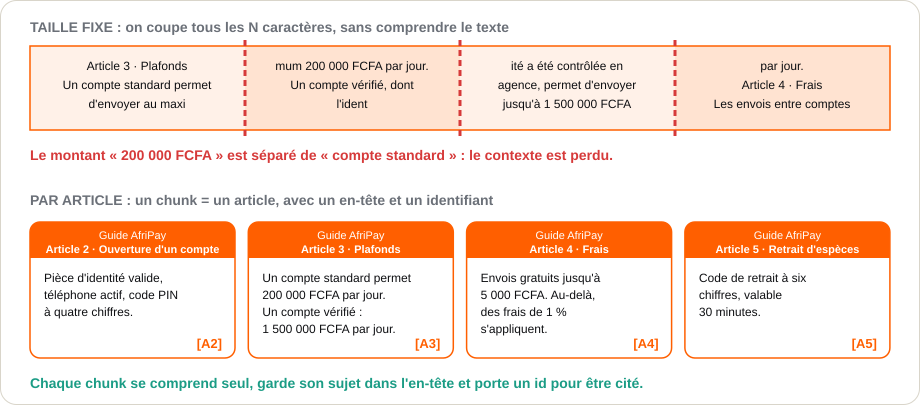

In [ ]:
schema("chunking")

### Essai n°1 : taille fixe

In [ ]:
def decouper_taille_fixe(texte, taille=200, chevauchement=0):
    """Coupe le texte tous les `taille` caractères, sans tenir compte du sens."""
    pas = taille - chevauchement
    return [texte[i:i + taille] for i in range(0, len(texte), pas)]

morceaux = decouper_taille_fixe(DOCUMENT, taille=200)
print(f"{len(morceaux)} morceaux\n")

# Quel morceau contient le plafond d'envoi ?
morceau_plafond = [m for m in morceaux if "200 000" in m][0]
print(morceau_plafond)

15 morceaux

mum 200 000 FCFA par jour et de conserver un solde maximal de 1 000 000 FCFA. Un compte vérifié, dont l'identité a été contrôlée en agence, permet d'envoyer jusqu'à 1 500 000 FCFA par jour.

Article 4


**À observer.** Ce morceau commence au milieu d'un mot (« mum »), se termine par le début de l'article suivant, et
ne dit pas **à quel type de compte** s'applique le premier montant. Un modèle qui ne verrait que ce morceau
pourrait répondre faux (par exemple confondre compte standard et compte vérifié). C'est le problème du **contexte perdu** vu en cours :
un chunk doit rester compréhensible tout seul.

### Essai n°2 : un chunk = un article, avec un en-tête

On coupe aux frontières naturelles du document et on ajoute en tête de chaque chunk le **titre du document** et le
**titre de l'article**. Le sujet reste ainsi visible pour la recherche, même si le texte ne le répète pas.
Chaque chunk garde aussi un `id` (pour **citer**) et une `source` (pour **afficher**).

In [ ]:
def decouper_par_article(texte, titre_document):
    """Un chunk = un article. Chaque chunk reçoit un en-tête, un id et une source."""
    motif = re.compile(r"^Article (\d+) — (.+)$", re.MULTILINE)
    reperes = list(motif.finditer(texte))
    chunks = []
    for i, repere in enumerate(reperes):
        debut = repere.end()
        fin = reperes[i + 1].start() if i + 1 < len(reperes) else len(texte)
        numero, titre = repere.group(1), repere.group(2)
        corps = texte[debut:fin].strip()
        chunks.append({
            "id": f"A{numero}",                                    # sert à citer : [A3]
            "source": f"{titre_document}, article {numero}",       # sert à afficher
            "texte": f"{titre_document} — Article {numero} — {titre}\n{corps}",
        })
    return chunks

CHUNKS = decouper_par_article(DOCUMENT, "Guide AfriPay")
tailles = [len(c["texte"]) for c in CHUNKS]
print(f"{len(CHUNKS)} chunks, de {min(tailles)} à {max(tailles)} caractères\n")
print(CHUNKS[2]["id"], "→", CHUNKS[2]["source"])
print(CHUNKS[2]["texte"])

12 chunks, de 145 à 335 caractères

A3 → Guide AfriPay, article 3
Guide AfriPay — Article 3 — Plafonds
Un compte standard permet d'envoyer au maximum 200 000 FCFA par jour et de conserver un solde maximal de 1 000 000 FCFA. Un compte vérifié, dont l'identité a été contrôlée en agence, permet d'envoyer jusqu'à 1 500 000 FCFA par jour.


## Étape 3 · Les embeddings

Un **embedding** transforme un texte en une liste de nombres (un **vecteur**) qui représente son **sens** :
deux textes qui parlent de la même chose ont des vecteurs proches, même sans mot en commun.

Trois détails importants :

- Le modèle `multilingual-e5` demande un préfixe : `"passage: "` pour les documents, `"query: "` pour les questions.
  Les deux fonctions ci-dessous s'en chargent.
- `normalize_embeddings=True` donne des vecteurs de longueur 1 : le **produit scalaire** est alors égal à la
  **similarité cosinus**.
- Le **même modèle** doit servir à indexer les documents et à encoder les questions.

La première exécution télécharge le modèle (environ 0,5 Go, une seule fois).

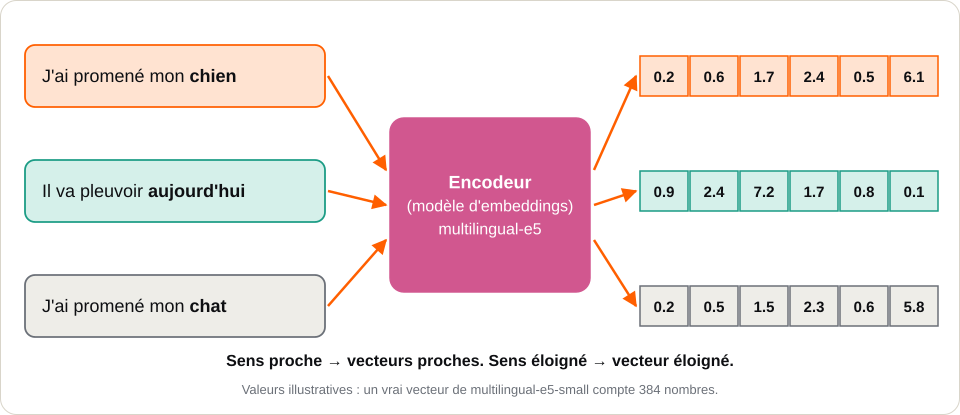

In [ ]:
schema("embeddings")

In [ ]:
from sentence_transformers import SentenceTransformer

modele = SentenceTransformer(MODELE_EMBEDDINGS)

def vecteurs_passages(textes):
    return modele.encode(["passage: " + t for t in textes], normalize_embeddings=True)

def vecteur_question(question):
    return modele.encode("query: " + question, normalize_embeddings=True)

V = vecteurs_passages([c["texte"] for c in CHUNKS])     # un vecteur par chunk
print("Forme de V :", V.shape, "→ (nombre de chunks, dimensions du vecteur)")

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/498k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

Forme de V : (12, 384) → (nombre de chunks, dimensions du vecteur)


### Chercher par le sens

Notre « base vectorielle » tient ici dans un tableau NumPy `V`. Chercher, c'est :

1. encoder la question en vecteur ;
2. calculer sa similarité avec chaque chunk (`V @ vecteur`) ;
3. garder les **k meilleurs** (le « top-k »).

Les vraies bases vectorielles (Chroma, FAISS, Qdrant…) font la même chose, mais plus vite, avec de grands volumes,
la sauvegarde sur disque et le filtrage par métadonnées.

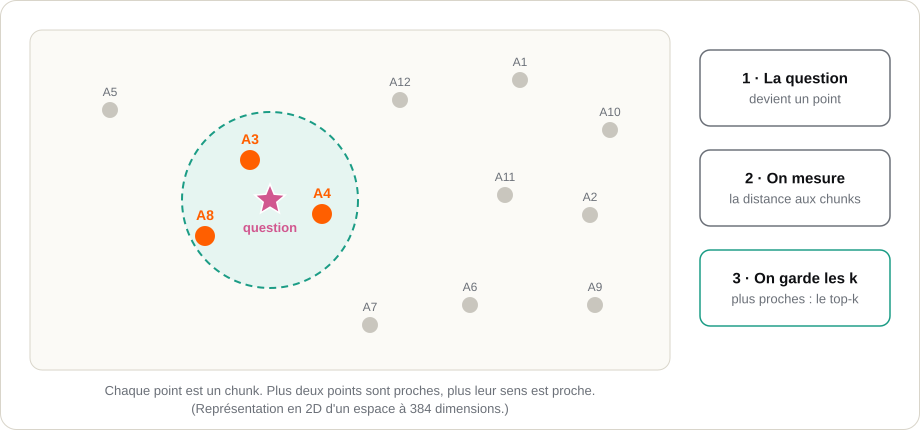

In [ ]:
schema("recherche")

In [ ]:
def recherche_dense(question, k=3):
    scores = V @ vecteur_question(question)          # un score par chunk
    meilleurs = np.argsort(scores)[::-1][:k]         # indices des k plus grands scores
    return [(CHUNKS[i], float(scores[i])) for i in meilleurs]

def afficher(resultats):
    for rang, (chunk, score) in enumerate(resultats, start=1):
        titre = chunk["texte"].splitlines()[0]
        print(f"{rang}. [{chunk['id']}] score={score:.3f} | {titre}")

Q_PARAPHRASE = "Quelle somme maximale puis-je transférer en une journée ?"
afficher(recherche_dense(Q_PARAPHRASE))

1. [A3] score=0.842 | Guide AfriPay — Article 3 — Plafonds
2. [A6] score=0.818 | Guide AfriPay — Article 6 — Perte ou vol du téléphone
3. [A8] score=0.814 | Guide AfriPay — Article 8 — Codes d'erreur


**À observer.** La question dit « somme maximale », « transférer », « journée » ; le document dit « plafonds »,
« envoyer », « par jour ». Peu de mots sont communs. Le bon article remonte-t-il quand même ?

## Étape 4 · Mots-clés, vecteurs ou les deux ?

| Méthode | Principe | Points forts | Point faible |
| --- | --- | --- | --- |
| **BM25** | compte les **mots identiques** à ceux de la question | codes, noms propres, termes exacts | ne voit pas les synonymes |
| **Dense** | compare les **sens** (embeddings) | paraphrases, synonymes | peut manquer un code précis |
| **Hybride** | fusionne les deux classements | profite des deux | un peu plus de code |

### BM25 (recherche par mots-clés)

In [ ]:
from rank_bm25 import BM25Okapi

def mots(texte):
    """Découpe un texte en mots minuscules (accents conservés)."""
    return re.findall(r"[a-zà-ÿ0-9\-]+", texte.lower())

BM25 = BM25Okapi([mots(c["texte"]) for c in CHUNKS])

def recherche_bm25(question, k=3):
    scores = BM25.get_scores(mots(question))
    meilleurs = np.argsort(scores)[::-1][:k]
    return [(CHUNKS[i], float(scores[i])) for i in meilleurs]

afficher(recherche_bm25(Q_PARAPHRASE))

1. [A7] score=0.902 | Guide AfriPay — Article 7 — Code PIN oublié
2. [A6] score=0.803 | Guide AfriPay — Article 6 — Perte ou vol du téléphone
3. [A9] score=0.661 | Guide AfriPay — Article 9 — Réclamations


### L'hybride : fusionner les classements avec RRF

Les scores de BM25 et du dense n'ont **pas la même échelle** : on ne peut pas les additionner.
**Reciprocal Rank Fusion (RRF)** ignore les scores et ne regarde que les **rangs** : un chunk reçoit
`1 / (60 + rang)` points dans chaque liste, puis on additionne. Un chunk bien classé par les deux méthodes gagne.
On demande plus de candidats (`candidats=10`) à chaque méthode que le top-k final, pour laisser la fusion travailler.

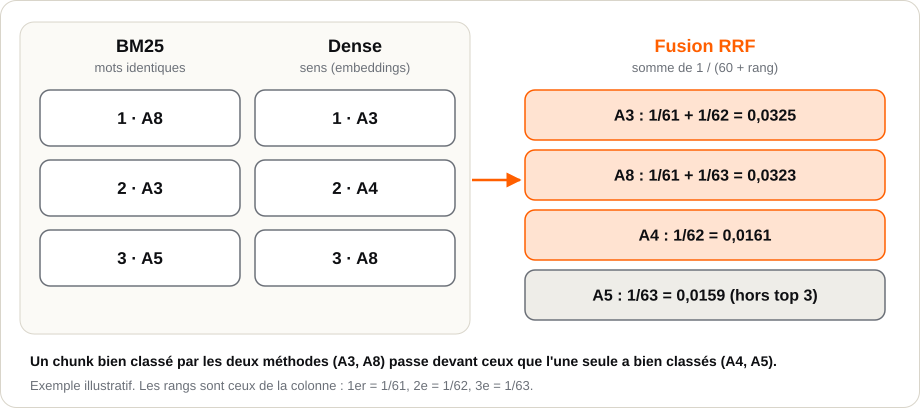

In [ ]:
schema("hybride")

In [ ]:
PAR_ID = {c["id"]: c for c in CHUNKS}

def recherche_hybride(question, k=3, candidats=10):
    listes = [recherche_dense(question, candidats), recherche_bm25(question, candidats)]
    points = {}
    for liste in listes:
        for rang, (chunk, _) in enumerate(liste, start=1):
            points[chunk["id"]] = points.get(chunk["id"], 0) + 1 / (60 + rang)
    classement = sorted(points, key=points.get, reverse=True)[:k]
    return [(PAR_ID[i], points[i]) for i in classement]

METHODES = {"BM25": recherche_bm25, "Dense": recherche_dense, "Hybride": recherche_hybride}

def comparer(question, k=3):
    print("Question :", question)
    for nom, methode in METHODES.items():
        ids = [chunk["id"] for chunk, _ in methode(question, k)]
        print(f"  {nom:8} → {ids}")
    print()

Q_CODE = "Que signifie l'erreur E-204 ?"
comparer(Q_PARAPHRASE)
comparer(Q_CODE)

Question : Quelle somme maximale puis-je transférer en une journée ?
  BM25     → ['A7', 'A6', 'A9']
  Dense    → ['A3', 'A6', 'A8']
  Hybride  → ['A6', 'A3', 'A9']

Question : Que signifie l'erreur E-204 ?
  BM25     → ['A8', 'A9', 'A7']
  Dense    → ['A8', 'A6', 'A7']
  Hybride  → ['A8', 'A9', 'A7']



**À observer.** Comparez les trois lignes pour chaque question.

- Pour la **paraphrase**, quelle méthode place l'article 3 en tête ? BM25, qui cherche des mots identiques, a-t-il des raisons de réussir ?
- Pour le **code `E-204`**, un terme exact et rare : que fait chaque méthode ?

C'est la raison d'être de l'hybride : ne pas dépendre d'un seul type de signal.
Essayez vos propres questions en modifiant `Q_CODE` ci-dessus.

## Étape 5 · Générer la réponse

On assemble un **prompt** qui sépare clairement trois choses : les **règles**, les **passages** retrouvés et la **question**.
Trois règles font la différence entre un RAG fiable et un LLM qui improvise :

1. **Répondre uniquement avec les passages**, sans connaissances extérieures.
2. **Dire `INFORMATION ABSENTE`** quand les passages ne suffisent pas.
3. **Citer l'identifiant** du passage entre crochets après chaque affirmation, par exemple `[A3]`.

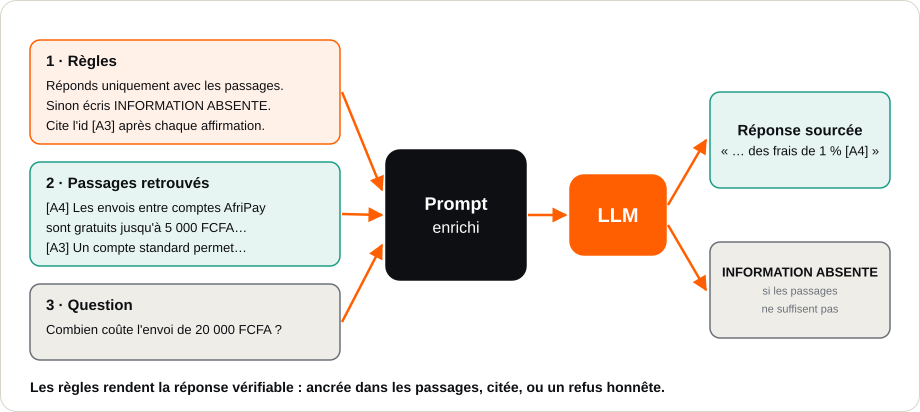

In [ ]:
schema("prompt")

In [ ]:
PROMPT = """Tu réponds uniquement à partir des passages fournis.

Règles :
- Si les passages ne permettent pas de répondre, écris exactement :NFORMATION ABSENTE
- Après chaque affirmation, cite l'identifiant du passage entre crochets, par exemple [A3 I].
- N'utilise jamais tes connaissances générales.

Passages :
{contexte}

Question : {question}"""

def construire_prompt(question, passages):
    contexte = "\n\n".join(f"[{p['id']}] {p['texte']}" for p in passages)
    return PROMPT.format(contexte=contexte, question=question)

def demander_au_llm(prompt):
    """Envoie le prompt au LLM. Renvoie None si aucune API n'est configurée."""
    if not mode_api:
        return None
    from openai import OpenAI
    client = OpenAI(api_key=API_KEY, base_url=BASE_URL)
    reponse = client.chat.completions.create(
        model=MODELE_LLM,
        temperature=0,                                   # réponses stables d'un essai à l'autre
        messages=[{"role": "user", "content": prompt}],
    )
    return reponse.choices[0].message.content

def repondre(question, k=3, methode=recherche_hybride):
    """Le RAG complet : chercher, assembler le prompt, générer."""
    passages = [chunk for chunk, _ in methode(question, k)]
    prompt = construire_prompt(question, passages)
    reponse = demander_au_llm(prompt)
    print("Question :", question)
    print("Passages retenus :", [p["id"] for p in passages], "\n")
    if reponse is None:
        print("── Mode sans API : collez ce prompt dans un assistant de votre choix ──\n")
        print(prompt)
    else:
        print("Réponse :", reponse)
    return reponse, passages

reponse, passages = repondre("Combien me coûte l'envoi de 20 000 FCFA à un autre utilisateur ?")

Question : Combien me coûte l'envoi de 20 000 FCFA à un autre utilisateur ?
Passages retenus : ['A3', 'A4', 'A8'] 

── Mode sans API : collez ce prompt dans un assistant de votre choix ──

Tu réponds uniquement à partir des passages fournis.

Règles :
- Si les passages ne permettent pas de répondre, écris exactement :NFORMATION ABSENTE
- Après chaque affirmation, cite l'identifiant du passage entre crochets, par exemple [A3 I].
- N'utilise jamais tes connaissances générales.

Passages :
[A3] Guide AfriPay — Article 3 — Plafonds
Un compte standard permet d'envoyer au maximum 200 000 FCFA par jour et de conserver un solde maximal de 1 000 000 FCFA. Un compte vérifié, dont l'identité a été contrôlée en agence, permet d'envoyer jusqu'à 1 500 000 FCFA par jour.

[A4] Guide AfriPay — Article 4 — Frais
Les envois entre comptes AfriPay sont gratuits jusqu'à 5 000 FCFA. Au-delà, des frais de 1 % s'appliquent, plafonnés à 1 500 FCFA. Le retrait chez un agent coûte 1,5 % du montant. Les paiements

### Que se passe-t-il quand la réponse n'est pas dans le document ?

C'est le test le plus important d'un RAG honnête. Le guide ne parle pas de taux de change : le système doit **refuser**
plutôt qu'inventer. Avec une API, la réponse attendue est exactement `INFORMATION ABSENTE`.

In [ ]:
Q_HORS_DOCUMENT = "Quel est le taux de change entre le FCFA et le dollar sur AfriPay ?"
reponse_hors, passages_hors = repondre(Q_HORS_DOCUMENT)

Question : Quel est le taux de change entre le FCFA et le dollar sur AfriPay ?
Passages retenus : ['A4', 'A3', 'A1'] 

── Mode sans API : collez ce prompt dans un assistant de votre choix ──

Tu réponds uniquement à partir des passages fournis.

Règles :
- Si les passages ne permettent pas de répondre, écris exactement :NFORMATION ABSENTE
- Après chaque affirmation, cite l'identifiant du passage entre crochets, par exemple [A3 I].
- N'utilise jamais tes connaissances générales.

Passages :
[A4] Guide AfriPay — Article 4 — Frais
Les envois entre comptes AfriPay sont gratuits jusqu'à 5 000 FCFA. Au-delà, des frais de 1 % s'appliquent, plafonnés à 1 500 FCFA. Le retrait chez un agent coûte 1,5 % du montant. Les paiements chez un commerçant sont gratuits pour le client.

[A3] Guide AfriPay — Article 3 — Plafonds
Un compte standard permet d'envoyer au maximum 200 000 FCFA par jour et de conserver un solde maximal de 1 000 000 FCFA. Un compte vérifié, dont l'identité a été contrôlée en agenc

## Étape 6 · Contrôler et évaluer

Un RAG qui « a l'air de marcher » ne suffit pas : il faut **mesurer**. Deux contrôles simples.

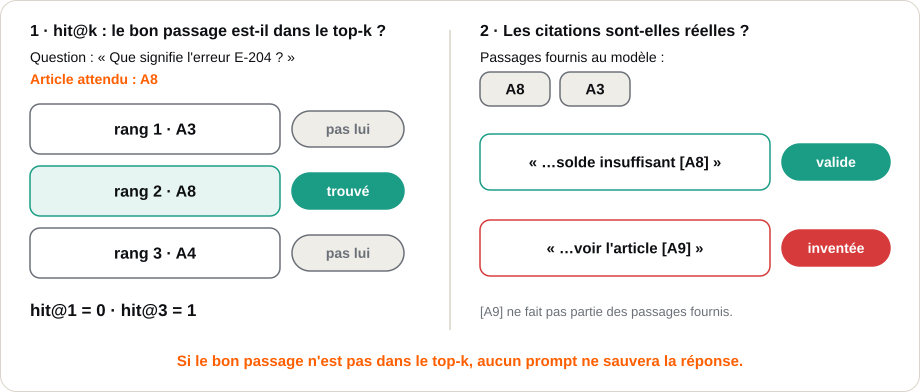

In [ ]:
schema("evaluation")

### Contrôle 1 : les citations sont-elles réelles ?

Cette vérification mécanique contrôle que chaque identifiant cité fait bien partie des passages fournis au modèle.
Elle détecte une **citation inventée**, mais pas une mauvaise interprétation d'un vrai passage : un humain reste nécessaire.

In [ ]:
def verifier_citations(reponse, passages):
    cites = set(re.findall(r"\[([A-Za-z0-9\-]+)\]", reponse))
    fournis = {p["id"] for p in passages}
    inventees = cites - fournis
    refus = "INFORMATION ABSENTE" in reponse
    return {
        "citations": sorted(cites),
        "inventees": sorted(inventees),
        "valide": refus or (bool(cites) and not inventees),   # un refus n'a pas besoin de citation
    }

if reponse:
    print(verifier_citations(reponse, passages))
else:
    print("Pas de réponse générée (mode sans API) : le contrôle s'applique à la réponse d'un LLM.")

Pas de réponse générée (mode sans API) : le contrôle s'applique à la réponse d'un LLM.


### Contrôle 2 : la recherche trouve-t-elle le bon passage ?

On prépare un **jeu de test** : des questions et, pour chacune, l'**article attendu**. Puis on mesure le **hit@k** :
dans combien de cas l'article attendu figure parmi les `k` premiers résultats ?

> **Bonne pratique :** écrivez ce jeu de test **avant** de regarder les scores, et si possible faites-le écrire par
> quelqu'un d'autre. Des questions rédigées après lecture des chunks reprennent leur vocabulaire et flattent le système.

Six questions, c'est trop peu pour conclure sur des écarts fins, mais assez pour repérer un système cassé.

In [ ]:
JEU_DE_TEST = [
    ("Quelle somme maximale puis-je transférer en une journée avec un compte standard ?", "A3"),
    ("Que signifie l'erreur E-204 ?",                                                      "A8"),
    ("On m'a volé mon téléphone, que dois-je faire ?",                                    "A6"),
    ("Combien me coûte l'envoi de 20 000 FCFA à un autre utilisateur ?",                  "A4"),
    ("Mon fils de 15 ans peut-il avoir un compte ?",                                      "A11"),
    ("J'ai envoyé de l'argent au mauvais destinataire, comment me faire rembourser ?",    "A9"),
]

def evaluer(jeu, ks=(1, 3)):
    """Pour chaque méthode : nombre de questions où l'article attendu est dans le top-k."""
    print(f"{'Méthode':10}" + "".join(f"hit@{k:<8}" for k in ks))
    for nom, methode in METHODES.items():
        ligne = ""
        for k in ks:
            reussites = sum(attendu in [c["id"] for c, _ in methode(q, k)] for q, attendu in jeu)
            ligne += f"{reussites}/{len(jeu):<9}"
        print(f"{nom:10}{ligne}")

evaluer(JEU_DE_TEST)

Méthode   hit@1       hit@3       
BM25      3/6        5/6        
Dense     5/6        6/6        
Hybride   4/6        5/6        


**À observer.** Quelle méthode réussit le mieux à `k=1` ? À `k=3` les écarts se réduisent : avec seulement 12 articles,
le bon passage se trouve vite dans le top 3. Sur un vrai document de 50 pages, `k=1` et `k=3` raconteraient
des histoires très différentes.

Quelles questions échouent ? Pour les trouver, regardez le détail avec `comparer(...)`.

**Ce qu'il faut retenir :** si le bon passage n'est pas dans ce que vous donnez au LLM, aucun prompt ne sauvera la réponse.
Le travail de qualité se joue d'abord dans la **recherche**.

## Étape 7 · À vous : votre RAG sur un vrai document

Vous avez maintenant tous les éléments. L'objectif : le **même système sur un document de votre choix**.

**Choisissez un document** de 10 à 30 pages, en **texte natif** (pas un PDF scanné, qui n'a pas de texte à extraire) :
un texte de loi de votre pays, les conditions d'un service de paiement, un règlement intérieur, un guide agricole,
un programme de cours…

Les cellules suivantes reprennent le travail des étapes précédentes sous forme de fonctions réutilisables.
Si vous ne changez rien, elles s'exécutent sur le document d'exemple : le notebook reste utilisable du début à la fin.

### 7.1 Charger votre document

In [ ]:
from pypdf import PdfReader

def lire_pdf(chemin):
    """Renvoie la liste des pages sous la forme (numéro, texte). Les pages sans texte sont ignorées."""
    pages = []
    for numero, page in enumerate(PdfReader(chemin).pages, start=1):
        texte = (page.extract_text() or "").strip()
        if texte:
            pages.append((numero, texte))
    return pages

# ✏️ À MODIFIER : mettez True pour téléverser votre PDF (Colab uniquement)
TELEVERSER_MON_PDF = True
TITRE_DOCUMENT = "Guide_agricole_pratique.pdf"          # ✏️ le titre qui apparaîtra dans l'en-tête des chunks

MES_PAGES = None
if TELEVERSER_MON_PDF:
    from google.colab import files
    fichier = list(files.upload())[0]
    MES_PAGES = lire_pdf(fichier)
    print(f"{len(MES_PAGES)} pages avec du texte")
    if not MES_PAGES:
        print("⚠️ Aucun texte extrait : le PDF est probablement scanné (il faudrait d'abord une étape d'OCR).")
else:
    print("Aucun PDF téléversé : l'exemple AfriPay sera utilisé.")

Saving Guide_agricole_pratique.pdf to Guide_agricole_pratique.pdf
20 pages avec du texte


### 7.2 Découper et indexer

`decouper_generique` regroupe les paragraphes d'une page jusqu'à une taille maximale, puis ajoute le même en-tête
(titre, page) que pour AfriPay. Les blocs trop longs sont recoupés avec un chevauchement.
`indexer` reconstruit tout ce qui dépend des chunks : vecteurs, index BM25 et table des identifiants.

> **À vous de décider** : `taille_max` (essayez 500, 800, 1200) et la stratégie. Pour un texte de loi,
> un chunk par article est souvent préférable. Notez votre choix et **justifiez-le** dans votre README.

In [ ]:
def decouper_generique(pages, titre, taille_max=800):
    """Regroupe les paragraphes de chaque page en chunks d'environ `taille_max` caractères."""
    chunks = []
    for numero, texte in pages:
        blocs, courant = [], ""
        for paragraphe in re.split(r"\n\s*\n", texte):
            paragraphe = paragraphe.strip()
            if not paragraphe:
                continue
            if courant and len(courant) + len(paragraphe) > taille_max:
                blocs.append(courant)
                courant = ""
            courant = (courant + "\n\n" + paragraphe).strip()
        if courant:
            blocs.append(courant)

        morceaux = []                                  # un bloc trop long est recoupé
        for bloc in blocs:
            if len(bloc) > taille_max * 1.5:
                morceaux += decouper_taille_fixe(bloc, taille_max, chevauchement=100)
            else:
                morceaux.append(bloc)

        for n, morceau in enumerate(morceaux, start=1):
            chunks.append({
                "id": f"P{numero}-{n}",                            # page 3, bloc 2 → [P3-2]
                "source": f"{titre}, page {numero}",
                "texte": f"{titre} — page {numero}\n{morceau}",
            })
    return chunks

def indexer(chunks):
    """Recalcule les vecteurs, l'index BM25 et la table des ids. Les fonctions de recherche s'adaptent seules."""
    global CHUNKS, V, BM25, PAR_ID
    CHUNKS = chunks
    V = vecteurs_passages([c["texte"] for c in CHUNKS])
    BM25 = BM25Okapi([mots(c["texte"]) for c in CHUNKS])
    PAR_ID = {c["id"]: c for c in CHUNKS}
    print(f"Index prêt : {len(CHUNKS)} chunks")

# ✏️ À MODIFIER : taille maximale des chunks (en caractères)
TAILLE_MAX = 800

if MES_PAGES:
    indexer(decouper_generique(MES_PAGES, TITRE_DOCUMENT, TAILLE_MAX))
else:
    print("Document d'exemple conservé (index AfriPay déjà prêt).")

tailles = [len(c["texte"]) for c in CHUNKS]
print(f"Taille des chunks : de {min(tailles)} à {max(tailles)} caractères")
for c in CHUNKS[:3]:
    print("\n[" + c["id"] + "]", c["texte"][:200].replace("\n", " ⏎ "), "…")

Index prêt : 49 chunks
Taille des chunks : de 52 à 838 caractères

[P1-1] Guide_agricole_pratique.pdf — page 1 ⏎ GUIDE AGRICOLE PRATIQUE  |  1  ⏎ REPÈRES DE TERRAIN  ⏎ Guide agricole   ⏎ pratique  ⏎ Organiser une production résiliente, préserver les ressources et décider  ⏎ à partir de …

[P2-1] Guide_agricole_pratique.pdf — page 2 ⏎ GUIDE AGRICOLE PRATIQUE  |  2  ⏎ AVANT DE COMMENCER  ⏎ Comment utiliser ce guide  ⏎ Une exploitation performante ne repose pas sur une recette unique. Elle combine un so …

[P2-2] Guide_agricole_pratique.pdf — page 2 ⏎ nt souvent mieux qu’un souvenir imprécis.   ⏎ Les conseils de ce guide ne remplacent ni une analyse de sol, ni un diagnostic agronomique, ni les consignes d’un  ⏎ tech …


### 7.3 Votre jeu de test

Écrivez **5 questions** dont la réponse se trouve dans votre document, avec l'`id` du chunk attendu (lisible dans les
extraits ci-dessus, ou en affichant `CHUNKS`). Ajoutez **1 question hors document** pour tester le refus.

In [ ]:
# ✏️ À MODIFIER : remplacez par vos questions et les ids de vos chunks
MON_JEU_DE_TEST = [
    ("Quelles informations faut-il noter pour établir le diagnostic initial d’une parcelle ?", "P3-1"),
    ("Quels sont les trois principes complémentaires de l’agriculture de conservation cités dans le guide ?", "P5-1"),
    ("Quels éléments faut-il prendre en compte pour planifier l’irrigation ?", "P7-1"),
    ("Que faut-il vérifier avant d’utiliser un produit phytopharmaceutique ?", "P9-1"),
    ("Quelles données consigner après la récolte pour évaluer les résultats de la culture ?", "P14-1"),
]

MA_QUESTION_HORS_DOCUMENT = "Quel est le prix du blé en dollars cette année ?"    # par exemple : "Quel est le prix en dollars ?"

if MON_JEU_DE_TEST:
    evaluer(MON_JEU_DE_TEST)
else:
    print("Ajoutez vos questions dans MON_JEU_DE_TEST pour lancer l'évaluation.")

if MA_QUESTION_HORS_DOCUMENT:
    reponse_hors_document, passages_hors_document = repondre(MA_QUESTION_HORS_DOCUMENT)
    if mode_api:
        assert reponse_hors_document == "INFORMATION ABSENTE"
    else:
        print("\n[Mode sans API] L'assertion a été sautée car le LLM n'a pas pu être interrogé.")

Méthode   hit@1       hit@3       
BM25      2/5        2/5        
Dense     1/5        1/5        
Hybride   2/5        2/5        
Question : Quel est le prix du blé en dollars cette année ?
Passages retenus : ['P15-2', 'P3-2', 'P15-1'] 

── Mode sans API : collez ce prompt dans un assistant de votre choix ──

Tu réponds uniquement à partir des passages fournis.

Règles :
- Si les passages ne permettent pas de répondre, écris exactement :NFORMATION ABSENTE
- Après chaque affirmation, cite l'identifiant du passage entre crochets, par exemple [A3 I].
- N'utilise jamais tes connaissances générales.

Passages :
[P15-2] Guide_agricole_pratique.pdf — page 15
on rendement 
ne garantit pas un bon résultat si le coût de production ou le déclassement augmente. 
Lorsque vous changez une pratique, comparez si possible une bande ou une parcelle témoin, tout en gardant les 
autres conditions aussi proches que possible. Répétez le test sur plusieurs saisons lorsque la météo pe ut fortement 
influe

### 7.4 Votre livrable

À rendre : **ce notebook complété** (ou un dépôt), un **README** court, et **vos 5 questions testées avec leurs sources**.

| Points | Critère | Comment le vérifier ici |
| --- | --- | --- |
| 6 | Le pipeline fonctionne de bout en bout | `repondre(...)` renvoie une réponse sur *votre* document |
| 4 | Le choix de découpage est justifié | `TAILLE_MAX` ou la stratégie, expliqués dans le README |
| 4 | Les réponses sont ancrées et sourcées | `verifier_citations(...)` ne signale aucune citation inventée |
| 3 | Le système dit « je ne sais pas » hors document | `MA_QUESTION_HORS_DOCUMENT` donne `INFORMATION ABSENTE` |
| 3 | README et tests clairs | `evaluer(MON_JEU_DE_TEST)` et les 5 questions documentés |

**Bonus :** un document dans une langue locale, une interface simple (Gradio ou Streamlit), ou deux stratégies
de découpage comparées avec `evaluer(...)`.

## Pour aller plus loin

Ce que vous avez construit est le **socle**. Les prochaines briques, dans l'ordre où on les ajoute en pratique :

- **Reranker** : après la recherche, un second modèle relit chaque paire (question, passage) et réordonne les candidats.
  Il améliore souvent la précision, mais ajoute de la latence et un modèle à héberger : mesurez avant d'adopter.
- **Vraie base vectorielle** (Chroma, Qdrant, pgvector…) : sauvegarde sur disque, mises à jour, filtres sur métadonnées.
  Prévoyez les métadonnées utiles **avant** d'indexer.
- **Évaluation automatique** (RAGAS, TruLens) : pertinence du contexte, fidélité, pertinence de la réponse.
- **Reformulation de requêtes** (multi-query, HyDE) : le LLM reformule la question avant la recherche.
- **Architectures avancées** : RAG agentique, GraphRAG, RAG multimodal.

**Règle d'or :** commencez simple, puis ajoutez une brique à la fois **en mesurant l'effet** sur votre jeu de test.
Un meilleur score moyen sur six questions ne prouve rien : agrandissez le jeu de test avant de conclure.